# Experiment A — RIMES / French TrOCR (independent run)
Compare baseline with six individual preprocessing techniques on identical RIMES lines. This notebook needs no Experiment A execution or saved IAM/Bentham results. Outputs live under results/experiment_a_rimes.

Default: 1000 validation lines (or the full split if smaller), seed 5112. Initial parameters are prespecified starting settings, **not RIMES validation-selected optima**. Develop on validation; switch to test only after freezing the protocol. Never tune from test results. No training or combinations.

Sources: [RIMES](https://huggingface.co/datasets/Teklia/RIMES-2011-line) and [French checkpoint](https://huggingface.co/dj0w/trocr-french-handwriting-v5/tree/6047032cbe5f3c7f17244a4c3dd21d9356f15480). Both Hub cards declare MIT. The community checkpoint reports RIMES plus custom-data fine-tuning; precise overlap with these published splits is unverified. Treat validation as development, not unseen generalization. Repository weight upload refers to V3 although its card now says V5; record that provenance uncertainty. Do not reuse the card's reported metrics as experimental results.

Processor RGB conversion, resize and normalization follow optional treatments consistently. No mandatory extra grayscale is imposed: the card's inference example uses RGB (its training description mentions grayscale). Scoring collapses whitespace and preserves accents, case and punctuation. Cross-language absolute scores confound dataset, checkpoint and training provenance.

In [12]:
from pathlib import Path
import sys, json, random, platform
from datetime import datetime, timezone
from importlib.metadata import version
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/load_dataset/rimes.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from huggingface_hub import HfApi
from src.load_dataset.rimes import load_rimes_dataset, DATASET_ID, FRENCH_CHECKPOINT, FRENCH_MODEL_REVISION
from src.models import TrOCRRecognizer
from src.preprocessing import (PreprocessingPipeline, Grayscale, NonLocalMeans, Deskew, CLAHE, IntensityNormalization, SizeNormalization)
from src.validation.denoising import adapt_image, evaluate, summarize

In [13]:
SPLIT = "test"
SAMPLE_COUNT = 1000
SEED = 5112
BATCH_SIZE = 8
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"  # Same accelerator as IAM when available.
DATASET_REVISION = None  # First run resolves main; paste saved SHA here for repeats.
CHECKPOINT = FRENCH_CHECKPOINT
MODEL_REVISION = FRENCH_MODEL_REVISION
GENERATION = {"max_new_tokens": 128, "num_beams": 1, "do_sample": False}
# Match Experiment A IAM decoding: greedy, no extra repetition penalties.
print("Device:", DEVICE, "| decoding:", GENERATION)
pipelines = {
    "baseline": PreprocessingPipeline(),
    "grayscale": PreprocessingPipeline((Grayscale(),)),
    "denoising": PreprocessingPipeline((NonLocalMeans(h=3),)),
    "deskew": PreprocessingPipeline((Deskew(max_angle=10, angle_step=0.5),)),
    "clahe": PreprocessingPipeline((CLAHE(clip_limit=2, tile_grid_size=(8, 8)),)),
    "intensity_normalization": PreprocessingPipeline((IntensityNormalization(),)),
    "size_normalization": PreprocessingPipeline((SizeNormalization(target_height=128),)),
}
assert SPLIT in ("validation", "test") and SAMPLE_COUNT > 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
frozen_config = {name: pipe.to_config() for name, pipe in pipelines.items()}
display(pd.DataFrame([{"configuration": k, "parameters": json.dumps(v)} for k, v in frozen_config.items()]))

Device: mps | decoding: {'max_new_tokens': 128, 'num_beams': 1, 'do_sample': False}


,configuration,parameters
0,baseline,"{""steps"": []}"
1,grayscale,"{""steps"": [{""name"": ""grayscale"", ""enabled"": tr..."
2,denoising,"{""steps"": [{""name"": ""non_local_means"", ""enable..."
3,deskew,"{""steps"": [{""name"": ""deskew"", ""enabled"": true,..."
4,clahe,"{""steps"": [{""name"": ""clahe"", ""enabled"": true, ..."
5,intensity_normalization,"{""steps"": [{""name"": ""intensity_normalization"",..."
6,size_normalization,"{""steps"": [{""name"": ""size_normalization"", ""ena..."


Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Split: test | full: 778 | selected: 778 | revision: ba3e6b5573094208b30a134e32d9b65dab18e74e


,source_index,text,mode,size
0,167,en constante augmentation.,L,"(1159, 128)"
1,36,J'ai bien reçu la commande passée la semaine d...,L,"(1287, 128)"
2,429,"Je souhaiterais, si possible, que vous",L,"(1203, 128)"
3,770,votre magazine et au lieu de les acheter tous les,L,"(2377, 128)"
4,56,d'actions boursières que je vous ai,L,"(1220, 128)"


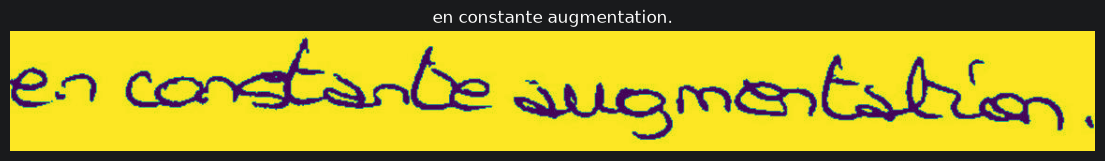

In [14]:
dataset_revision = HfApi().dataset_info(DATASET_ID, revision=DATASET_REVISION or "main").sha
full_dataset = load_rimes_dataset(SPLIT, revision=dataset_revision)
assert {"image", "text"}.issubset(full_dataset.column_names)
assert len(full_dataset) > 0
indices = random.Random(SEED).sample(range(len(full_dataset)), min(SAMPLE_COUNT, len(full_dataset)))
dataset = full_dataset.select(indices)
for row in dataset:
    if not isinstance(row["text"], str) or not row["text"].strip():
        raise ValueError("Missing RIMES transcription")
print("Split:", SPLIT, "| full:", len(full_dataset), "| selected:", len(dataset), "| revision:", dataset_revision)
display(pd.DataFrame([{"source_index": indices[i], "text": dataset[i]["text"],
                      "mode": dataset[i]["image"].mode, "size": dataset[i]["image"].size}
                     for i in range(min(5, len(dataset)))]))
fig, ax = plt.subplots(figsize=(14, 3))
ax.imshow(adapt_image(dataset[0]["image"]))
ax.set_title(dataset[0]["text"])
ax.axis("off")
plt.show()

In [15]:
# Re-run after changing decoding/device: creates a fresh run, preserving old predictions.
# Loads only the French model. First run downloads approximately 1.34 GB of weights.
model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION,
                        device=DEVICE, generation_kwargs=GENERATION)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = ROOT / "results/experiment_a_rimes" / SPLIT / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
from importlib.metadata import PackageNotFoundError, packages_distributions
import cv2
software = {p: version(p) for p in ("torch", "transformers", "datasets", "huggingface-hub", "pillow", "numpy", "pandas", "jiwer")}
# cv2 can be provided by standard, headless, contrib, or system builds.
software["cv2"] = cv2.__version__
for distribution in packages_distributions().get("cv2", []):
    try:
        software[distribution] = version(distribution)
    except PackageNotFoundError:
        software[distribution] = "distribution metadata unavailable"

metadata = {
    "decoding_protocol": "Experiment A IAM: greedy, max_new_tokens=128, do_sample=False",
    "experiment": "A-RIMES", "run_id": RUN_ID, "dataset": DATASET_ID,
    "dataset_revision": dataset_revision, "dataset_fingerprint": dataset._fingerprint,
    "split": SPLIT, "full_split_count": len(full_dataset), "sample_count": len(dataset),
    "source_indices": indices, "seed": SEED, "batch_size": BATCH_SIZE,
    "model": model.to_config(), "configurations": frozen_config,
    "selection_policy": "prespecified initial settings; no IAM/Bentham selections reused",
    "normalization": "collapse whitespace; preserve accents, case and punctuation",
    "training_overlap": "RIMES fine-tuning reported; exact split overlap unverified",
    "software": software,
    "python": platform.python_version(),
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
pd.DataFrame({"index": range(len(indices)), "source_index": indices}).to_csv(OUTPUT_DIR / "samples.csv", index=False)
print("Results:", OUTPUT_DIR)

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

Results: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/experiment_a_rimes/test/20261116T010633641656Z


In [16]:
# Baseline always runs first; batch predictions are saved after every batch.
summaries = []
for name, pipeline in pipelines.items():
    assert pipeline.to_config() == frozen_config[name]
    summaries.append(evaluate(dataset, "rimes", model, name, pipeline, OUTPUT_DIR, BATCH_SIZE))
comparison, ranking, winners = summarize(summaries, OUTPUT_DIR)
display(comparison[["configuration", "sample_count", "cer", "wer", "cer_delta_vs_baseline", "wer_delta_vs_baseline"]])
print("CER/WER are corpus fractions; negative deltas indicate improvement.")

rimes/baseline: 8/778
rimes/baseline: 80/778
rimes/baseline: 160/778
rimes/baseline: 240/778
rimes/baseline: 320/778
rimes/baseline: 400/778
rimes/baseline: 480/778
rimes/baseline: 560/778
rimes/baseline: 640/778
rimes/baseline: 720/778
rimes/baseline: 778/778
rimes/grayscale: 8/778
rimes/grayscale: 80/778
rimes/grayscale: 160/778
rimes/grayscale: 240/778
rimes/grayscale: 320/778
rimes/grayscale: 400/778
rimes/grayscale: 480/778
rimes/grayscale: 560/778
rimes/grayscale: 640/778
rimes/grayscale: 720/778
rimes/grayscale: 778/778
rimes/denoising: 8/778
rimes/denoising: 80/778
rimes/denoising: 160/778
rimes/denoising: 240/778
rimes/denoising: 320/778
rimes/denoising: 400/778
rimes/denoising: 480/778
rimes/denoising: 560/778
rimes/denoising: 640/778
rimes/denoising: 720/778
rimes/denoising: 778/778
rimes/deskew: 8/778
rimes/deskew: 80/778
rimes/deskew: 160/778
rimes/deskew: 240/778
rimes/deskew: 320/778
rimes/deskew: 400/778
rimes/deskew: 480/778
rimes/deskew: 560/778
rimes/deskew: 640/778


,configuration,sample_count,cer,wer,cer_delta_vs_baseline,wer_delta_vs_baseline
0,baseline,778,0.053475,0.180528,0.000000,0.000000
1,grayscale,778,0.053475,0.180528,0.000000,0.000000
2,denoising,778,0.053646,0.180528,0.000170,0.000000
3,deskew,778,0.058817,0.191878,0.005342,0.011350
4,clahe,778,0.052594,0.179819,-0.000881,-0.000709
5,intensity_normalization,778,0.053475,0.180528,0.000000,0.000000
6,size_normalization,778,0.053475,0.180528,0.000000,0.000000


CER/WER are corpus fractions; negative deltas indicate improvement.


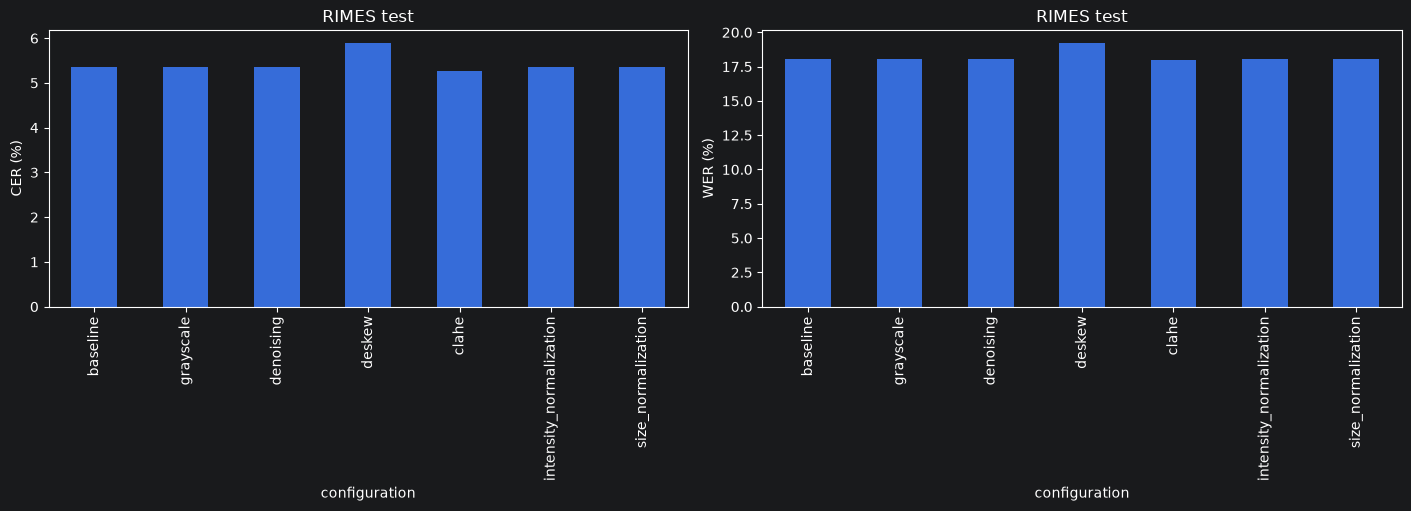

,index,ground_truth,prediction,cer,wer
0,0,en constante augmentation.,en constante augmentation.,0.000000,0.000000
1,1,J'ai bien reçu la commande passée la semaine d...,J'ai bien reçu la commande passée la semrine d...,0.016949,0.100000
2,2,"Je souhaiterais, si possible, que vous","Je souhaiterais, si possible : que vous",0.052632,0.333333
3,3,votre magazine et au lieu de les acheter tous les,votre magazine et au vien de les acheter tous les,0.040816,0.100000
4,4,d'actions boursières que je vous ai,d'actions bonsieres que je vous ai,0.085714,0.166667
5,5,concernant la souscription d'une assurance vie...,"concernant la sourrigion d'une assurance vie, ...",0.058824,0.111111
6,6,C'est avec beaucoup de plaisir que l'an dernie...,C'est avec beaucoup de plaisir que l'an dernie...,0.015152,0.166667
7,7,salutations distinguées.,salutations distinguées.,0.000000,0.000000
8,8,Conformément aux règles de modifications de do...,(onfor némat aux régles de modifications de de...,0.176471,0.636364
9,9,moi de compter sur votre réponse.,mai de comples sur votre réponse.,0.090909,0.333333


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
for ax, metric in zip(axes, ("cer", "wer")):
    comparison.set_index("configuration")[metric].mul(100).plot.bar(ax=ax)
    ax.set_ylabel(metric.upper() + " (%)")
    ax.set_title("RIMES " + SPLIT)
fig.savefig(OUTPUT_DIR / "cer_wer.png", dpi=160, bbox_inches="tight")
plt.show()
predictions = pd.read_csv(OUTPUT_DIR / "rimes/baseline/predictions.csv", keep_default_na=False)
display(predictions[["index", "ground_truth", "prediction", "cer", "wer"]].head(10))

Results include metadata, original source indices, per-treatment identities, predictions, corpus summaries, comparison CSV and chart. Re-executing the inference cell can resume within this OUTPUT_DIR; rerunning model/output setup creates a fresh run. Preserve the run's dataset SHA for reproduction. Review validation results before planning a frozen final test evaluation; this notebook never reads previous Experiment A outputs.